# 06 · Embeddings with Sentence Transformers


In [1]:
%pip install -q sentence-transformers scikit-learn pandas

## Load the embedding model


In [2]:
from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print("Embedding model ready")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model ready


## Embed a mini knowledge base


In [3]:
knowledge = [
    {"id": "python_basics", "text": "Python uses indentation to define code blocks and supports many programming styles."},
    {"id": "model_training", "text": "Machine learning training adjusts model parameters using examples and an objective function."},
    {"id": "vector_search", "text": "Semantic search retrieves passages whose vector representations are close to a query embedding."},
    {"id": "nutrition", "text": "A balanced diet includes appropriate energy, protein, fats, carbohydrates, vitamins, and minerals."},
    {"id": "database", "text": "A relational database stores structured information in tables linked by keys."},
]
texts = [item["text"] for item in knowledge]
vectors = model.encode(texts, normalize_embeddings=True)
print("Embedding matrix shape:", vectors.shape)

Embedding matrix shape: (5, 384)


## Search by meaning


In [4]:
def search(query, top_k=3):
    query_vector = model.encode([query], normalize_embeddings=True)
    scores = (query_vector @ vectors.T)[0]
    order = np.argsort(scores)[::-1][:top_k]
    return [
        {"score": float(scores[i]), **knowledge[i]}
        for i in order
    ]

for hit in search("How does retrieval find related passages?", top_k=3):
    print(f"{hit['score']:.3f} | {hit['id']} | {hit['text']}")

0.573 | vector_search | Semantic search retrieves passages whose vector representations are close to a query embedding.
0.304 | database | A relational database stores structured information in tables linked by keys.
0.156 | model_training | Machine learning training adjusts model parameters using examples and an objective function.


## Inspect similarity matrix


In [5]:
matrix = cosine_similarity(vectors)
labels = [item["id"] for item in knowledge]
pd.DataFrame(matrix, index=labels, columns=labels).round(2)

,python_basics,model_training,vector_search,nutrition,database
python_basics,1.00,0.14,0.05,0.01,0.13
model_training,0.14,1.00,0.16,0.05,0.12
vector_search,0.05,0.16,1.00,-0.01,0.35
nutrition,0.01,0.05,-0.01,1.00,0.02
database,0.13,0.12,0.35,0.02,1.00


## Optional: visualize embeddings


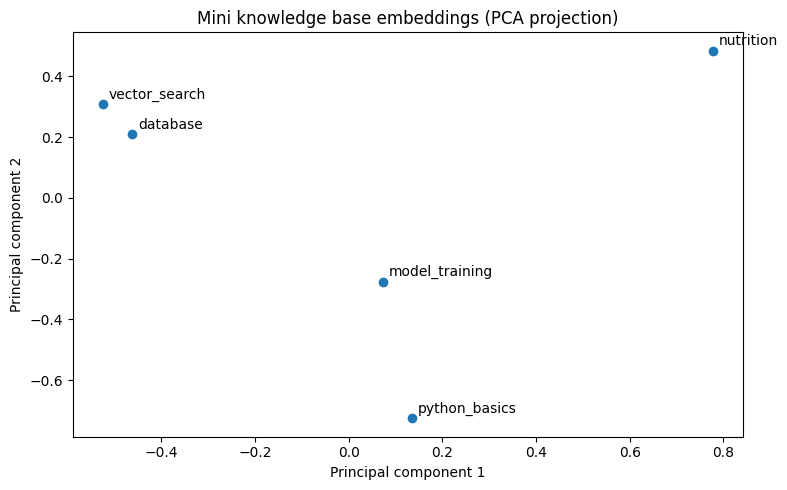

In [6]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

points = PCA(n_components=2).fit_transform(vectors)
plt.figure(figsize=(8, 5))
plt.scatter(points[:, 0], points[:, 1])
for i, label in enumerate(labels):
    plt.annotate(label, (points[i, 0], points[i, 1]), xytext=(4, 4),
                 textcoords="offset points")
plt.title("Mini knowledge base embeddings (PCA projection)")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.tight_layout()
plt.show()